# 4.1 - code from module-3

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [5]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

/home/jihad/miniconda3/envs/ml_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


np.float64(0.8034066713981547)

# 4.2 - accuracy and dummy model

### finding best threshold

In [6]:
len(y_val)

1409

In [ ]:
# amader validation set e total 1409 jon customer ase.

# churn_decision holo amader model er prediction. y_pred e threshold apply kore churn decision paisi.

(y_val == churn_decision).sum()

np.int64(1132)

In [ ]:
# 1409 joner moddhe 1132 joner prediction ei correct korse. so accuracy holo: 

(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [9]:
# so model er accuracy holo 80 percent. ekhon ei accuracy ber kora hoise threshold 0.5 dhore. ekhon ami bivinno range er threshold dhore model er accuracy dekhbo.

np.linspace(0, 1, 21) # 0 theke 1 er moddhe 20 ta value dibe equally distance er

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [17]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    churn_decision = (y_pred>=t)
    score = (y_val == churn_decision).mean()
    scores.append(score)

    print(f'thresholds = {t:.2f} and accuracy = {score: .3f}')

thresholds = 0.00 and accuracy =  0.274
thresholds = 0.05 and accuracy =  0.509
thresholds = 0.10 and accuracy =  0.591
thresholds = 0.15 and accuracy =  0.666
thresholds = 0.20 and accuracy =  0.710
thresholds = 0.25 and accuracy =  0.739
thresholds = 0.30 and accuracy =  0.760
thresholds = 0.35 and accuracy =  0.772
thresholds = 0.40 and accuracy =  0.785
thresholds = 0.45 and accuracy =  0.793
thresholds = 0.50 and accuracy =  0.803
thresholds = 0.55 and accuracy =  0.801
thresholds = 0.60 and accuracy =  0.795
thresholds = 0.65 and accuracy =  0.786
thresholds = 0.70 and accuracy =  0.765
thresholds = 0.75 and accuracy =  0.744
thresholds = 0.80 and accuracy =  0.735
thresholds = 0.85 and accuracy =  0.726
thresholds = 0.90 and accuracy =  0.726
thresholds = 0.95 and accuracy =  0.726
thresholds = 1.00 and accuracy =  0.726


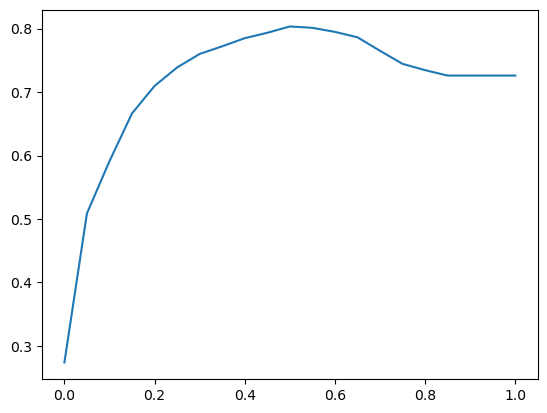

In [18]:
# uporer chart theke dekhtesi ami 0.5 threshold er jonnei best accuracy paitesi. eta graph e dekhi.

plt.plot(thresholds, scores)

In [20]:
# uporer etogula threshold and scores ber korsi eta scikit-learn diye korar way:

from sklearn.metrics import accuracy_score

# single accuracy
accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

In [22]:
# now multiple threshold

thresholds = np.linspace (0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    scores.append(score)

    print(f'thresholds = {t:.2f} and accuracy = {score: .3f}')
    

thresholds = 0.00 and accuracy =  0.274
thresholds = 0.05 and accuracy =  0.509
thresholds = 0.10 and accuracy =  0.591
thresholds = 0.15 and accuracy =  0.666
thresholds = 0.20 and accuracy =  0.710
thresholds = 0.25 and accuracy =  0.739
thresholds = 0.30 and accuracy =  0.760
thresholds = 0.35 and accuracy =  0.772
thresholds = 0.40 and accuracy =  0.785
thresholds = 0.45 and accuracy =  0.793
thresholds = 0.50 and accuracy =  0.803
thresholds = 0.55 and accuracy =  0.801
thresholds = 0.60 and accuracy =  0.795
thresholds = 0.65 and accuracy =  0.786
thresholds = 0.70 and accuracy =  0.765
thresholds = 0.75 and accuracy =  0.744
thresholds = 0.80 and accuracy =  0.735
thresholds = 0.85 and accuracy =  0.726
thresholds = 0.90 and accuracy =  0.726
thresholds = 0.95 and accuracy =  0.726
thresholds = 1.00 and accuracy =  0.726


### dummy model

In [23]:
'''
1. ami threshold 1 dile model er accurcy hoitese 72%.

2. threshold 1 mane ki? 
    এখানে 1 মানে হলো ১.০০ বা ১০০% সম্ভাবনা। তুমি যখন কোডে লেখো y_pred >= 1.0, তখন তুমি মডেলকে শর্ত দিচ্ছ— "যার Probability একদম কাঁটায় কাঁটায় ১০০% বা তার চেয়ে বেশি, তুমি কেবল তাকেই 'Churn করবে' বলবে। একটু কম হলেও 'না' বলবে।"

    এখন বাস্তব দুনিয়ায় কোনো মেশিন লার্নিং মডেলই কোনো বিষয়ে একদম ১০০% নিশ্চিত হতে পারে না। মডেলের দেওয়া Probability সর্বোচ্চ হয়তো ০.৯৯ (বা ৯৯%) হতে পারে, কিন্তু ১.০০ বা ১০০% হয় না।

    যেহেতু কারোরই Probability ১.০০ এর সমান বা বেশি হয় না, তাই মডেল বাধ্য হয়ে ওই ১৪০৯ জন কাস্টমারের সবার ক্ষেত্রেই উত্তর দেয় "False" বা "না, সে Churn করবে না"।

3. and etai dummy model. mane dataset e shobaikei bolbe je churn korbe na. and actully amader dataset er 73 percent asholei churn kore na. so dummy modle 73 percent accurate.

4. ei dhoroner dataset ke class imbalance bole. and class imbalance er khetre accuracy ke khub ekta believe kora jay na.
'''

pass

In [26]:
len(y_pred)

1409

In [ ]:
# dummy model
from collections import Counter
Counter(y_pred >= 1)

Counter({np.False_: 1409})

In [28]:
# amader dummy model bollo dataset er keu ei churn korbe na.

# 0 means not churn and 1 means churn

y_val.mean() # so matro 27 percent churn korse according to dummy model. 

np.float64(0.2739531582682754)

In [ ]:
1 - y_val.mean() # etai dummy model er accuracy. which is 72 percent.

np.float64(0.7260468417317246)

In [ ]:
# now question holo. dummy model er accuracy jodi 72 percent hoy then amra eto kosto kore dataset prepare kore code likhe model banaya accuracy pailam 80 percent. lav ki? 

# ejonnei ekhon matric gula use kobo nicher module e.